In [1]:
# 引入需要使用的包
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from matplotlib import pyplot as plt

In [2]:
# 读原始数据
data = pd.read_csv('chapter3_task_data.csv')
data.head()

,pay1,pay2,y
0,2.946794,0.057996,1
1,10.202126,8.798162,0
2,13.962240,89.794215,1
3,106.090589,45.969875,1
4,80.713481,112.575403,1


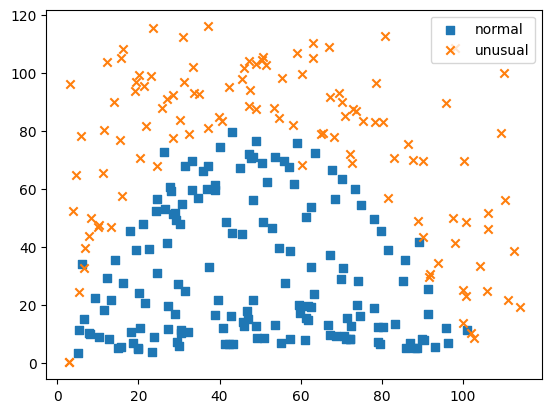

In [3]:
# 画原始数据图
fig1 = plt.figure()
mask = data.loc[:,'y']==0
normal = plt.scatter(data.loc[:,'pay1'][mask],data.loc[:,'pay2'][mask],marker=',')
unusual = plt.scatter(data.loc[:,'pay1'][~mask],data.loc[:,'pay2'][~mask],marker='x')
plt.legend((normal,unusual),('normal','unusual'))
plt.show()

In [4]:
# 使用二阶变量来训练逻辑回归模型
x1 = data.loc[:,'pay1']
x2 = data.loc[:,'pay2']
y = data.loc[:,'y']
x_2dim_dic = {'x1':x1,'x2':x2,'x1_2':x1**2,'x2_2':x2**2,'x1_x2':x1*x2}
x_2dim = pd.DataFrame(x_2dim_dic)
x_2dim

,x1,x2,x1_2,x2_2,x1_x2
0,2.946794,0.057996,8.683594,0.003364,0.170903
1,10.202126,8.798162,104.083382,77.407648,89.759956
2,13.962240,89.794215,194.944133,8063.001119,1253.728345
3,106.090589,45.969875,11255.213180,2113.229365,4876.971089
4,80.713481,112.575403,6514.666088,12673.221428,9086.352726
...,...,...,...,...,...
268,63.106069,105.032558,3982.375960,11031.838324,6628.191890
269,16.319302,108.318191,266.319628,11732.830588,1767.677311
270,19.384102,38.966938,375.743406,1518.422231,755.339090
271,63.468372,72.150112,4028.234191,5205.638650,4579.250113


In [5]:
# 训练逻辑回归模型
lr = LogisticRegression()
lr.fit(x_2dim,y)

/Users/mima0000/anaconda3/envs/ai_tec/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:460: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [6]:
# 评估模型
y_predict = lr.predict(x_2dim)
acs = accuracy_score(y,y_predict)
acs

0.967032967032967

In [7]:
# 获取五个theta值
theta0 = lr.intercept_[0]
theta1,theta2,theta3,theta4,theta5 = lr.coef_[0]
print(theta0,theta1,theta2,theta3,theta4,theta5)

3.3014882486212516 -1.0076213383836874 0.06702390813992096 0.009492390770042073 0.001756079097659855 0.0017594292108700437


In [8]:
# 求解x2关于x1的方程
def new_x2(x1):
    a = theta4
    b = theta5*x1+theta2
    c = theta0+theta1*x1+theta3*x1*x1
    pos_x2_new = (-b+np.sqrt(b**2-4*a*c))/(2*a)
    nei_x2_new = (-b-np.sqrt(b**2-4*a*c))/(2*a)
    return pos_x2_new,nei_x2_new

In [9]:
x1 = x1.sort_values()
pos_x2 = new_x2(x1)[0]
pos_x2

/Users/mima0000/anaconda3/envs/ai_tec/lib/python3.11/site-packages/pandas/core/arraylike.py:396: RuntimeWarning: invalid value encountered in sqrt
  result = getattr(ufunc, method)(*inputs, **kwargs)


89     -9.284205
0      -6.900659
155    -2.520163
200     5.314017
14     13.047533
         ...    
95    -37.743957
48    -40.288295
92    -47.427802
243          NaN
214          NaN
Name: pay1, Length: 273, dtype: float64

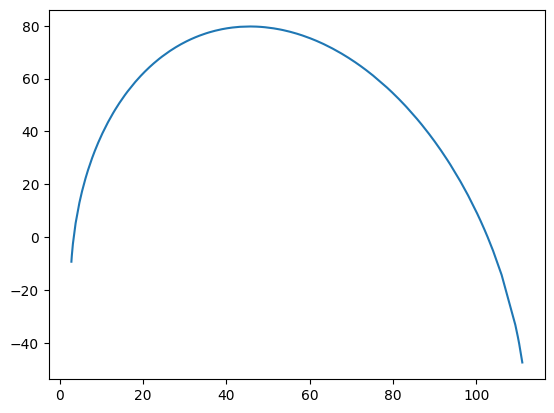

In [10]:
# 画出边界函数
fig2 = plt.figure()
plt.plot(x1,pos_x2)
plt.show()

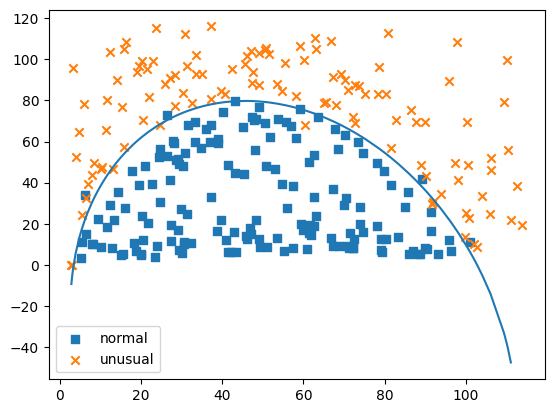

In [11]:
# 补上数据点
fig3 = plt.figure()
normal = plt.scatter(data.loc[:,'pay1'][mask],data.loc[:,'pay2'][mask],marker=',')
unusual = plt.scatter(data.loc[:,'pay1'][~mask],data.loc[:,'pay2'][~mask],marker='x')
plt.legend((normal,unusual),('normal','unusual'))
plt.plot(x1,pos_x2)
plt.show()

In [12]:
# 预测给出的数据，pay1 = 70,pay2 = 15,预测结果为1是异常
# 先处理给出的数据
x_test1 = 70
x_test2 = 15
x_test_dic = {'x1':x_test1,'x2':x_test2,'x1_2':x_test1**2,'x2_2':x_test2**2,'x1_x2':x_test1*x_test2}
x_test = pd.DataFrame(x_test_dic,index=[0])
x_test

,x1,x2,x1_2,x2_2,x1_x2
0,70,15,4900,225,1050


In [13]:
# 预测结果
print('unusual' if lr.predict(x_test) else 'normal')

normal
